In [2]:
import xarray as xr
linea_base_ch4 = xr.open_dataset("Linea_Base_CH4_AMG.nc")["CH4"]
print("Línea base cargada")

Línea base cargada


In [4]:
cubo_ch4 = xr.open_dataset("Cubo_CH4_Final.nc")["CH4"]

print("Cubo cargado")

Cubo cargado


In [5]:
import matplotlib.pyplot as plt
import geopandas as gpd
import folium
import numpy as np
import matplotlib.dates as mdates

In [14]:
linea_base_viento = xr.open_dataset("Linea_Base_Viento_AMG.nc")
poligono_amg = gpd.read_file("amg_limites.geojson").to_crs("EPSG:4326")
cubo_viento = xr.open_dataset("Cubo_Viento_AMG_Final.nc")

In [18]:
!pip install windrose

In [7]:
linea_base_ch4 = cubo_ch4.mean(dim="time", skipna=True)
media_linea_base_ch4 = linea_base_ch4.mean(
    dim=["y", "x"], skipna=True
).item()
print(f"Media Histórica Global del AMG   : {media_linea_base_ch4:.2f} ppb")

Media Histórica Global del AMG   : 1904.64 ppb


In [11]:
media_linea_base_ch4 = linea_base_ch4.mean(skipna=True)

valor_medio_ch4 = media_linea_base_ch4.item()

print(f"Valor Promedio : {valor_medio_ch4} ppb")

Valor Promedio : 1904.6422119140625 ppb


In [7]:
linea_base_ch4 = cubo_ch4.mean(dim="time", skipna=True)
media_linea_base_ch4 = linea_base_ch4.mean(
    dim=["y", "x"], skipna=True
).item()
print(f"Media Histórica Global del AMG   : {media_linea_base_ch4:.2f} ppb")

Media Histórica Global del AMG   : 1904.64 ppb


In [11]:
media_linea_base_ch4 = linea_base_ch4.mean(skipna=True)

valor_medio_ch4 = media_linea_base_ch4.item()

print(f"Valor Promedio : {valor_medio_ch4} ppb")

Valor Promedio : 1904.6422119140625 ppb


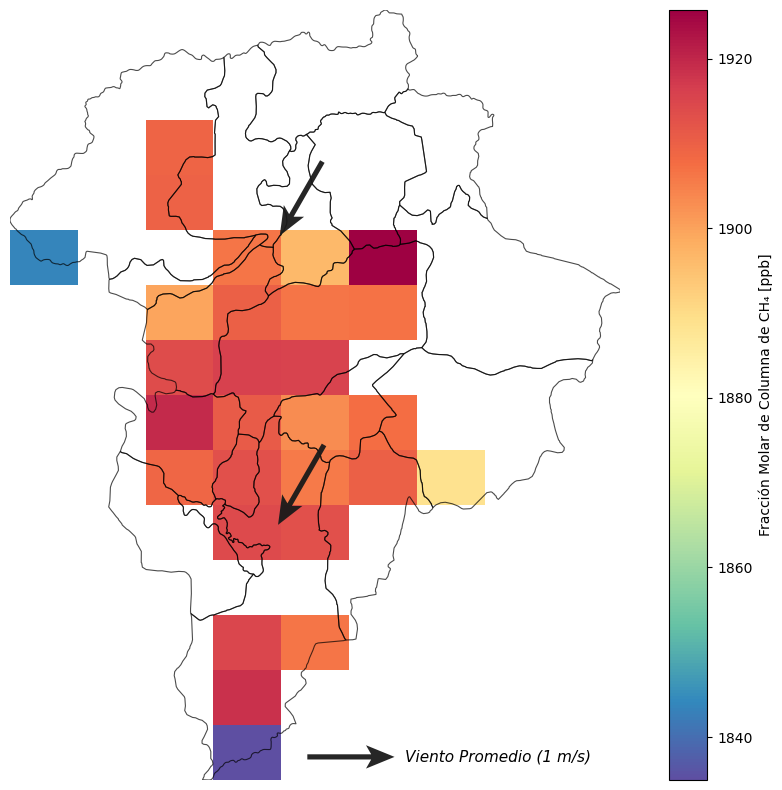

In [15]:
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr


linea_base_viento = xr.open_dataset("mystorage/Linea_Base_Viento_AMG.nc")
poligono_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(10, 8))

linea_base_ch4.plot(
    ax=ax,
    cmap="Spectral_r",
    cbar_kwargs={
        'label': 'Fracción Molar de Columna de CH₄ [ppb]'
    }
)

poligono_amg.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.8,
    alpha=0.7
)

U = linea_base_viento['u10'].values
V = linea_base_viento['v10'].values
X = linea_base_viento.longitude.values
Y = linea_base_viento.latitude.values

q = ax.quiver(
    X, Y, U, V,
    color='#1A1A1A',
    pivot='middle',
    scale=7,            
    width=0.0085,
    headwidth=4.5,
    headlength=5.5,
    alpha=0.95,
    zorder=5
)

ax.quiverkey(
    q, X=0.63, Y=0.03, U=1,
    label='Viento Promedio (1 m/s)',
    labelpos='E',
    coordinates='axes',
    fontproperties={'size': 11, 'style': 'italic'}
)

ax.set_title("")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig("mapa_linea_base_ch4_viento.png", dpi=300, bbox_inches='tight')
plt.show()

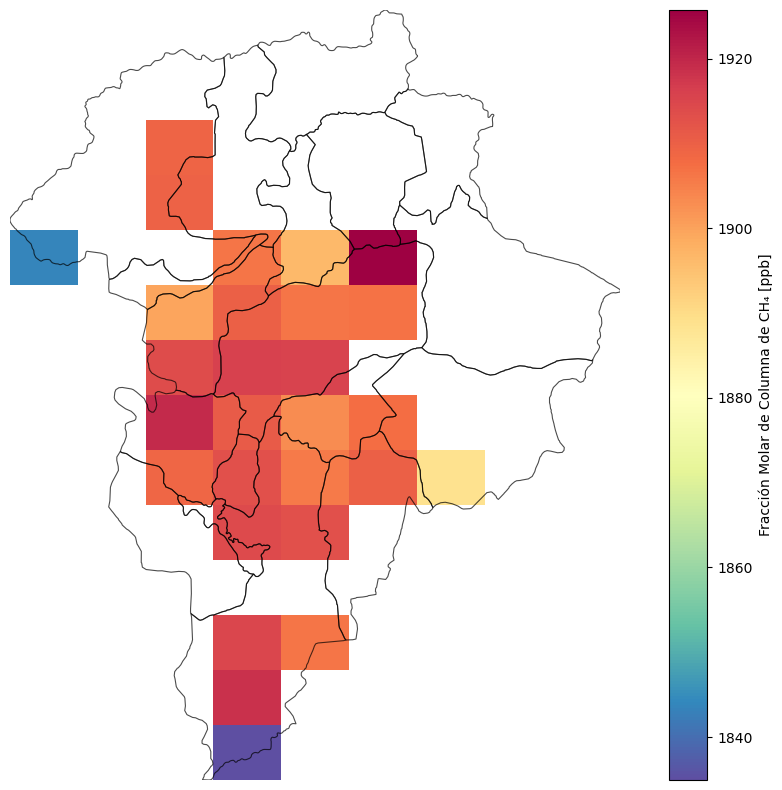

In [4]:
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr


poligono_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(10, 8))

linea_base_ch4.plot(
    ax=ax,
    cmap="Spectral_r",
    cbar_kwargs={
        'label': 'Fracción Molar de Columna de CH₄ [ppb]'
    }
)

poligono_amg.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.8,
    alpha=0.7
)

ax.set_title("")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig("mapa_linea_base_ch4.png", dpi=300, bbox_inches='tight')
plt.show()

Media Histórica Global del AMG   : 1904.64 ppb
Mediana Histórica Global del AMG : 1905.88 ppb
Diferencia (Sesgo por extremos)  : 1.23 ppb (0.06%)
Valor Pico en el Hotspot (Media)  : 1925.77 ppb
Valor Pico en el Hotspot (Mediana): 1925.77 ppb


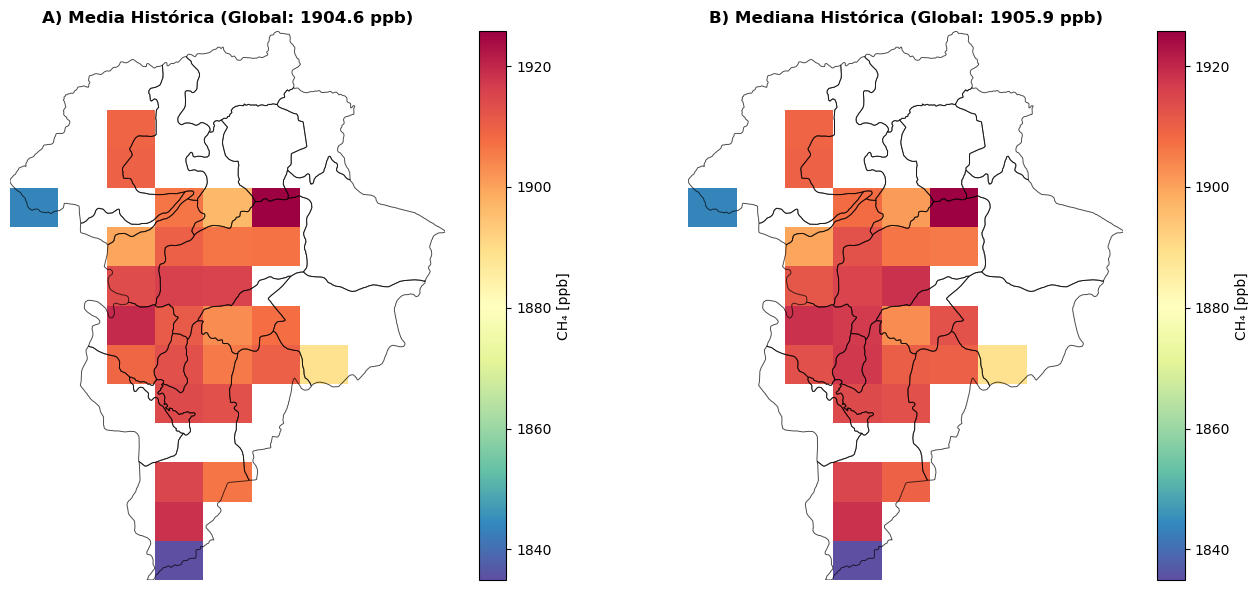

In [11]:
import numpy as np

ch4_mediana = cubo_ch4.median(dim="time", skipna=True)

media_global_ch4 = linea_base_ch4.mean(skipna=True).item()
mediana_global_ch4 = ch4_mediana.mean(skipna=True).item()
diferencia_absoluta = abs(media_global_ch4 - mediana_global_ch4)
diferencia_porcentual = (diferencia_absoluta / media_global_ch4) * 100

max_media_ch4 = linea_base_ch4.max(skipna=True).item()
max_mediana_ch4 = ch4_mediana.max(skipna=True).item()

print(f"Media Histórica Global del AMG   : {media_global_ch4:.2f} ppb")
print(f"Mediana Histórica Global del AMG : {mediana_global_ch4:.2f} ppb")
print(f"Diferencia (Sesgo por extremos)  : {diferencia_absoluta:.2f} ppb ({diferencia_porcentual:.2f}%)")
print(f"Valor Pico en el Hotspot (Media)  : {max_media_ch4:.2f} ppb")
print(f"Valor Pico en el Hotspot (Mediana): {max_mediana_ch4:.2f} ppb")

vmin_comun = min(linea_base_ch4.min().item(), ch4_mediana.min().item())
vmax_comun = max(max_media_ch4, max_mediana_ch4)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

linea_base_ch4.plot(
    ax=ax1, cmap="Spectral_r", vmin=vmin_comun, vmax=vmax_comun,
    cbar_kwargs={'label': 'CH₄ [ppb]'}
)
poligono_amg.plot(ax=ax1, facecolor="none", edgecolor="black", linewidth=0.7, alpha=0.7)
ax1.set_title(f"A) Media Histórica (Global: {media_global_ch4:.1f} ppb)", fontsize=12, fontweight="bold")
ax1.axis("off")

ch4_mediana.plot(
    ax=ax2, cmap="Spectral_r", vmin=vmin_comun, vmax=vmax_comun,
    cbar_kwargs={'label': 'CH₄ [ppb]'}
)
poligono_amg.plot(ax=ax2, facecolor="none", edgecolor="black", linewidth=0.7, alpha=0.7)
ax2.set_title(f"B) Mediana Histórica (Global: {mediana_global_ch4:.1f} ppb)", fontsize=12, fontweight="bold")
ax2.axis("off")

plt.tight_layout()
plt.show()

In [17]:
import folium
import numpy as np

lat_ch4 = 14.698568186785714
lon_ch4 = -90.42605087666666

serie_hotspot_ch4 = cubo_ch4.sel(x=lon_ch4, y=lat_ch4, method="nearest")
meses_validos = serie_hotspot_ch4.dropna(dim="time")

print(f"Total de meses con lectura válida en este píxel: {len(meses_validos)} de 84 meses")
print("\nFechas exactas y valores (ppb) registrados en esta coordenada:")
for fecha, valor in zip(meses_validos.time.dt.strftime('%Y-%m').values, meses_validos.values):
    print(f"  • {fecha}: {valor:.2f} ppb")

dx = 0.0629 / 2 
dy = 0.0494 / 2  

mapa_forense = folium.Map(location=[lat_ch4, lon_ch4], zoom_start=13, tiles="OpenStreetMap")

folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr='Google',
    name='Google Satellite Híbrido'
).add_to(mapa_forense)

limites_pixel = [[lat_ch4 - dy, lon_ch4 - dx], [lat_ch4 + dy, lon_ch4 + dx]]
folium.Rectangle(
    bounds=limites_pixel,
    color="#900C3F",
    weight=3,
    fill=True,
    fill_color="#C70039",
    fill_opacity=0.25,
    popup="Huella Real del Píxel de CH₄ (~7.0 x 5.5 km)"
).add_to(mapa_forense)

folium.Marker(
    location=[lat_ch4, lon_ch4],
    popup=f"Centroide Hotspot CH₄: {meses_validos.mean().item():.2f} ppb",
    icon=folium.Icon(color="red", icon="info-sign")
).add_to(mapa_forense)

folium.LayerControl().add_to(mapa_forense)
mapa_forense

Total de meses con lectura válida en este píxel: 2 de 84 meses

Fechas exactas y valores (ppb) registrados en esta coordenada:
  • 2021-11: 1931.11 ppb
  • 2024-02: 1920.43 ppb


In [18]:
import matplotlib.pyplot as plt
import pandas as pd

conteo_meses = cubo_ch4.count(dim="time")

df_pixeles = linea_base_ch4.to_dataframe(name="ch4_media").reset_index()
df_conteo = conteo_meses.to_dataframe(name="meses_validos").reset_index()
df_auditoria = pd.merge(
    df_pixeles, df_conteo[["y", "x", "meses_validos"]], on=["y", "x"]
)
df_auditoria = df_auditoria.dropna(subset=["ch4_media"]).sort_values(
    by="ch4_media", ascending=False
)

print(
    "Top 5 Píxeles con mayor Concentración de CH4, linea base"
)
print(df_auditoria[["y", "x", "ch4_media", "meses_validos"]].head(5).to_string(index=False))
print("-" * 70)

Top 5 Píxeles con mayor Concentración de CH4, linea base
        y          x   ch4_media  meses_validos
14.698568 -90.426051 1925.770996              2
14.554480 -90.609628 1919.536255              7
14.314332 -90.548436 1918.360840              2
14.602509 -90.548436 1916.009399             16
14.602509 -90.487243 1915.598999              9
----------------------------------------------------------------------


  [!] Amatitlán: Sin píxeles válidos
  [!] Chuarrancho: Sin píxeles válidos
  [!] Lago De Amatitlan: Excluido (Polígono menor a la grilla de 7.0 x 5.5 km)
  [!] Palencia: Sin píxeles válidos
  [!] San José del Golfo: Sin píxeles válidos
  [!] San Pedro Ayampuc: Sin píxeles válidos
  [!] San Pedro Sacatepéquez: Excluido (Polígono menor a la grilla de 7.0 x 5.5 km)


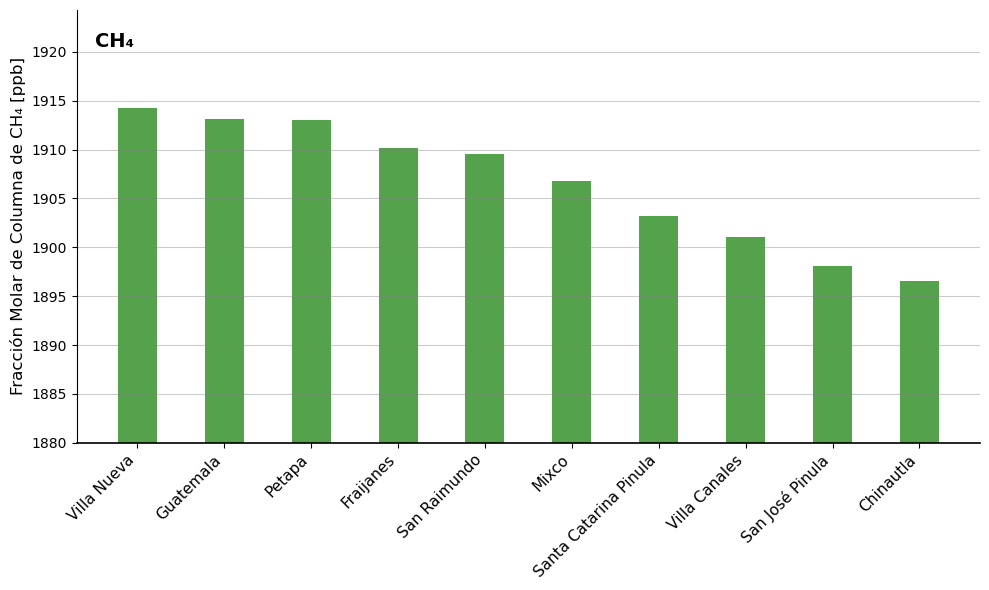


Ranking (top 10) de valores promedio de CH₄ ---
            Municipio     CH4_ppb
          Villa Nueva 1914.283447
            Guatemala 1913.080688
               Petapa 1913.037354
            Fraijanes 1910.152832
         San Raimundo 1909.598022
                Mixco 1906.739136
Santa Catarina Pinula 1903.240967
        Villa Canales 1901.101562
      San José Pinula 1898.067749
            Chinautla 1896.595093


In [10]:
import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np  # <- Necesario para np.isnan()
import pandas as pd

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs(
    "EPSG:4326"
)

col_nombre = [
    c
    for c in poligono_amg.columns
    if c.lower()
    in ["shape_name", "nombre", "municipio", "name", "adm2_es", "nom_mun"]
]
col_mun = col_nombre[0] if col_nombre else poligono_amg.columns[0]

resultados_municipios = []

matriz_ch4 = (
    linea_base_ch4 if "linea_base_ch4" in locals() else ch4_linea_base
)

for idx, row in poligono_amg.iterrows():
    nombre_mun = row[col_mun]
    geom = [row.geometry]
    try:
        recorte = matriz_ch4.rio.clip(
            geom, poligono_amg.crs, drop=True, all_touched=False
        )
        media_mun = float(recorte.mean(skipna=True).values)
        if not np.isnan(media_mun):
            resultados_municipios.append(
                {"Municipio": nombre_mun, "CH4_ppb": media_mun}
            )
        else:
            print(f"  [!] {nombre_mun}: Sin píxeles válidos")
    except Exception:
        print(
            f"  [!] {nombre_mun}: Excluido (Polígono menor a la grilla de 7.0 x 5.5 km)"
        )

df_mun_ch4 = pd.DataFrame(resultados_municipios)
df_ranking_ch4 = df_mun_ch4.sort_values(by="CH4_ppb", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    df_ranking_ch4["Municipio"],
    df_ranking_ch4["CH4_ppb"],
    color="#54A24B",
    width=0.45,
)

ax.text(
    0.02,
    0.95,
    "CH₄",
    transform=ax.transAxes,
    fontsize=14,
    fontweight="bold",
    va="top",
)

ax.set_ylabel("Fracción Molar de Columna de CH₄ [ppb]", fontsize=12)
ax.set_ylim(1880, df_ranking_ch4['CH4_ppb'].max() + 10)

plt.xticks(rotation=45, ha="right", fontsize=11)
ax.set_xlabel("")

ax.grid(axis="y", linestyle="-", alpha=0.4, color="gray")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1.2)

plt.tight_layout()
plt.savefig("Top10_Municipios_CH4.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nRanking (top 10) de valores promedio de CH₄ ---")
print(df_ranking_ch4[["Municipio", "CH4_ppb"]].to_string(index=False))

In [3]:
import folium

lat_ch4_real = 14.602509
lon_ch4_real = -90.548436

lat_vertedero_z3 = 14.6235
lon_vertedero_z3 = -90.5375

dx = 0.0629 / 2  
dy = 0.0494 / 2 

mapa_real = folium.Map(location=[lat_ch4_real, lon_ch4_real], zoom_start=13)

folium.TileLayer(
    tiles="https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}",
    attr="Google",
    name="Google Satellite Híbrido",
).add_to(mapa_real)

limites_pixel = [
    [lat_ch4_real - dy, lon_ch4_real - dx],
    [lat_ch4_real + dy, lon_ch4_real + dx],
]
folium.Rectangle(
    bounds=limites_pixel,
    color="#900C3F",
    weight=3,
    fill=True,
    fill_color="#C70039",
    fill_opacity=0.25,
    popup="Hotspot Crónico CH₄ (1916.01 ppb | n=16 meses)",
).add_to(mapa_real)

folium.Marker(
    location=[lat_ch4_real, lon_ch4_real],
    popup="Centroide Píxel (Zona 11): 1916.01 ppb (n=16)",
    icon=folium.Icon(color="red", icon="info-sign"),
).add_to(mapa_real)

folium.Marker(
    location=[lat_vertedero_z3, lon_vertedero_z3],
    popup="Relleno Sanitario Zona 3 (Fuente Principal de CH₄)",
    icon=folium.Icon(color="black", icon="trash"),
).add_to(mapa_real)

folium.LayerControl().add_to(mapa_real)
mapa_real

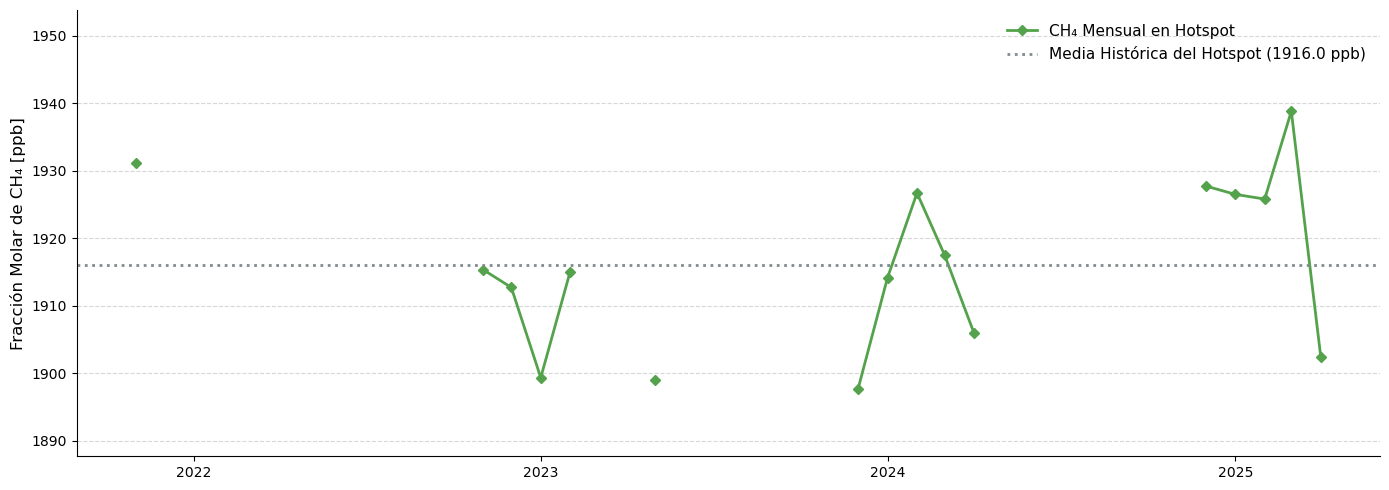

In [11]:

import rioxarray
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import rioxarray


lat_ch4_real = 14.602509
lon_ch4_real = -90.548436

hotspot_ts_ch4 = cubo_ch4.sel(x=lon_ch4_real, y=lat_ch4_real, method="nearest")

df_hotspot_ch4 = hotspot_ts_ch4.to_dataframe(name="CH4_ppb").reset_index()

valor_historico_ch4 = df_hotspot_ch4['CH4_ppb'].mean()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_hotspot_ch4['time'], df_hotspot_ch4['CH4_ppb'], 
        marker='D', markersize=5, color='#54A24B', linewidth=2, 
        label='CH₄ Mensual en Hotspot')

ax.axhline(valor_historico_ch4, 
           color='#7F8C8D', 
           linestyle=':', 
           linewidth=2,
           label=f'Media Histórica del Hotspot ({valor_historico_ch4:.1f} ppb)')

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.set_title("", fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel("Fracción Molar de CH₄ [ppb]", fontsize=12)
ax.set_xlabel("")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=False, fontsize=11)

min_y = df_hotspot_ch4['CH4_ppb'].min() - 10
max_y = df_hotspot_ch4['CH4_ppb'].max() + 15
ax.set_ylim(min_y, max_y)

plt.tight_layout()
plt.savefig("serie_tiempo_hotspot_ch4.png", dpi=300, bbox_inches='tight')
plt.show()

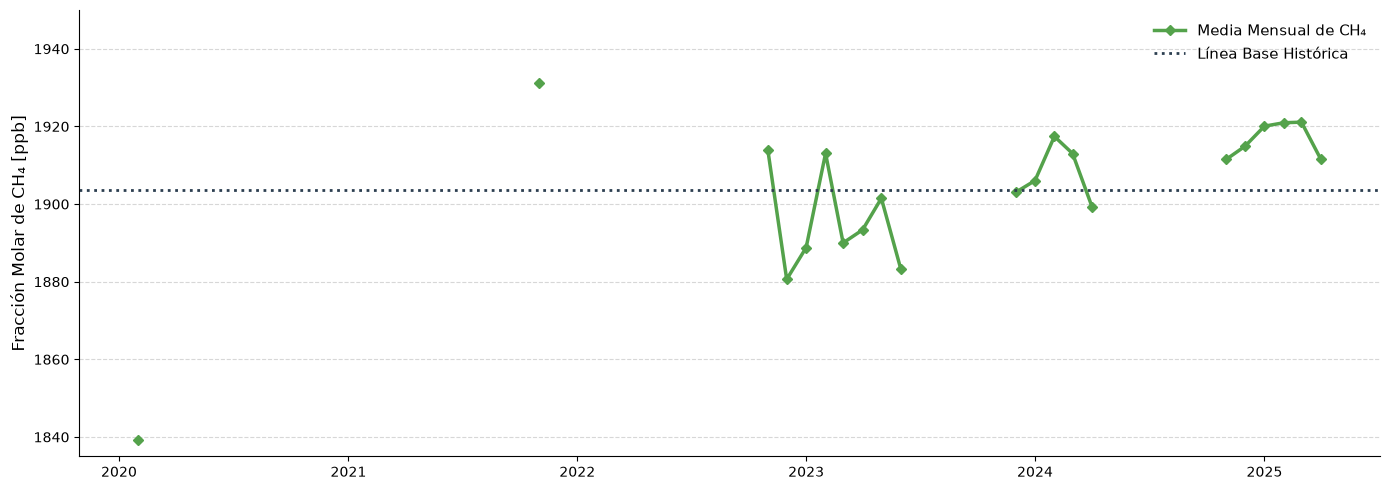

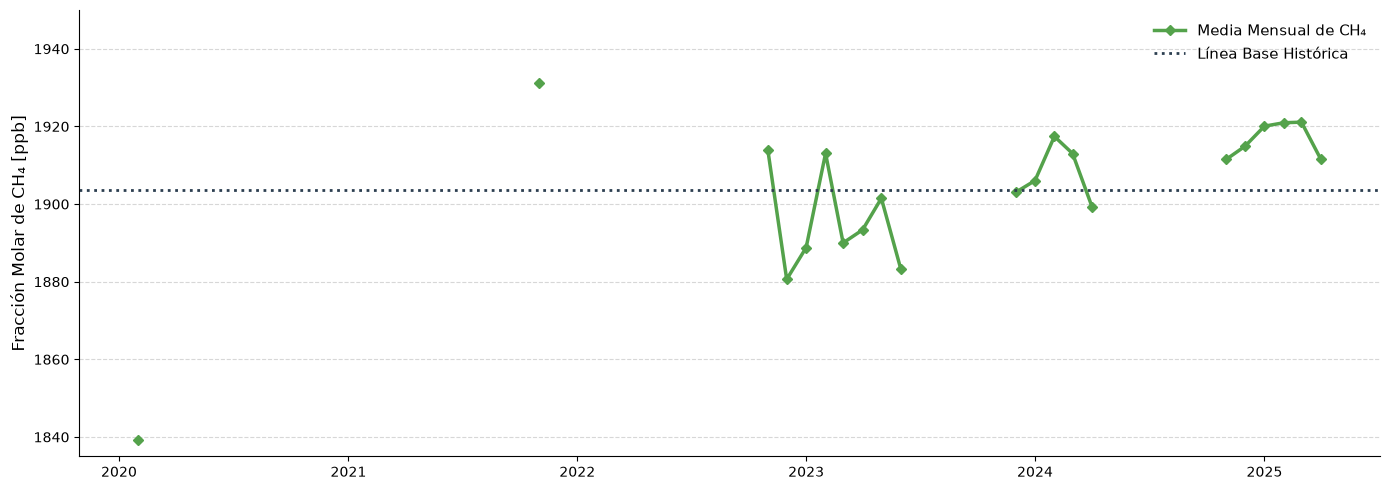

In [10]:
ts_ch4 = cubo_ch4.mean(dim=['x', 'y'], skipna=True)

df_ch4 = ts_ch4.to_dataframe(name="CH4_ppb").reset_index()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_ch4['time'], df_ch4['CH4_ppb'], 
        marker='D', markersize=5, color='#54A24B', linewidth=2.5, 
        label='Media Mensual de CH₄')

media_historica_ch4 = df_ch4['CH4_ppb'].mean()
ax.axhline(media_historica_ch4, 
           color='#2C3E50', 
           linestyle=':', 
           linewidth=2,
           label=f'Línea Base Histórica')

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.set_title("", fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel("Fracción Molar de CH₄ [ppb]", fontsize=12)
ax.set_xlabel("")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=False, fontsize=11)

ax.set_ylim(1835, 1950)
plt.tight_layout()
plt.savefig("serie_tiempo_global_ch4.png", dpi=300, bbox_inches='tight')
plt.show()

Años válidos por mes
     count         mean       median
Mes                                 
Ene      3  1904.971313  1906.049438
Feb      4  1897.698486  1915.245117
Mar      3  1908.041382  1913.018066
Abr      3  1901.392578  1899.294312
May      1  1901.491211  1901.491211
Jun      1  1883.264282  1883.264282
Jul      0          NaN          NaN
Ago      0          NaN          NaN
Sep      0          NaN          NaN
Oct      0          NaN          NaN
Nov      3  1918.819458  1913.841064
Dic      3  1899.507324  1903.003174


/tmp/ipykernel_105/1081279578.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


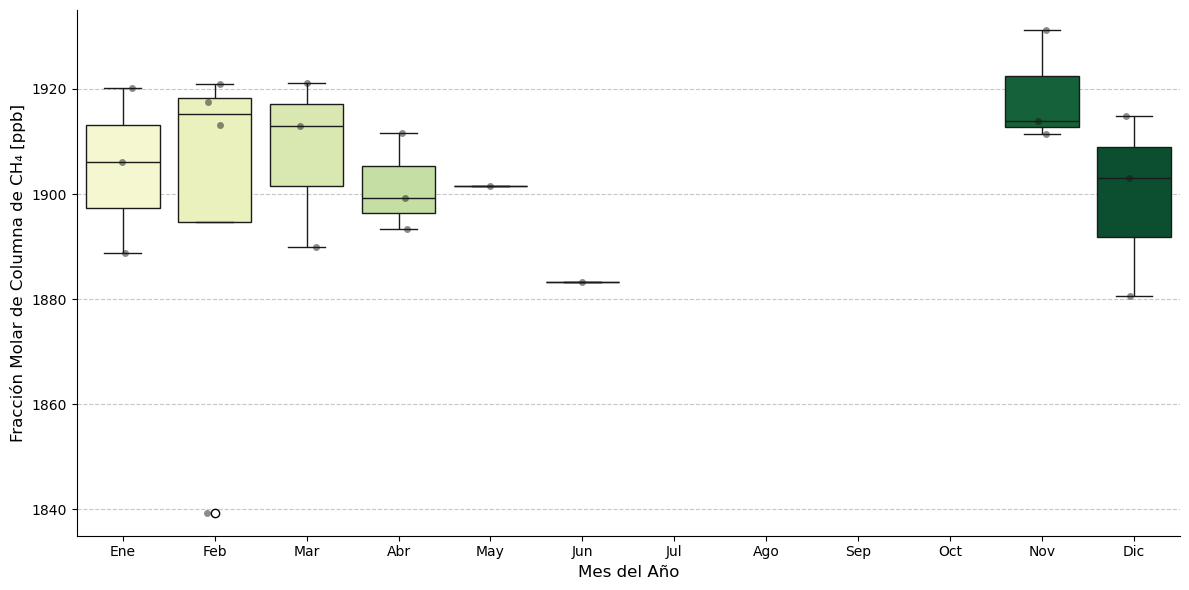

In [4]:
import seaborn as sns
import pandas as pd

ts_ch4 = cubo_ch4.mean(dim=['x', 'y'], skipna=True)

df_ch4 = ts_ch4.to_dataframe(name="CH4_ppb").reset_index()

df_ch4['Mes_Num'] = df_ch4['time'].dt.month

meses = {
    1: 'Ene',
    2: 'Feb',
    3: 'Mar',
    4: 'Abr',
    5: 'May',
    6: 'Jun',
    7: 'Jul',
    8: 'Ago',
    9: 'Sep',
    10: 'Oct',
    11: 'Nov',
    12: 'Dic',
}

df_ch4['Mes'] = df_ch4['Mes_Num'].map(meses)
df_ch4['Mes'] = pd.Categorical(
    df_ch4['Mes'],
    categories=[
        'Ene',
        'Feb',
        'Mar',
        'Abr',
        'May',
        'Jun',
        'Jul',
        'Ago',
        'Sep',
        'Oct',
        'Nov',
        'Dic',
    ],
    ordered=True,
)

print("Años válidos por mes")
conteo_mensual = df_ch4.groupby('Mes', observed=False)['CH4_ppb'].agg(
    ['count', 'mean', 'median']
)
print(conteo_mensual.to_string())

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=df_ch4,
    x='Mes',
    y='CH4_ppb',
    palette="YlGn",
    ax=ax,
    flierprops=dict(
        marker='o', markerfacecolor='white', markeredgecolor='black', markersize=6
    ),
)

sns.stripplot(
    data=df_ch4,
    x='Mes',
    y='CH4_ppb',
    color='#1A1A1A',
    alpha=0.5,
    size=5,
    jitter=0.1,
    ax=ax,
)

ax.set_ylabel("Fracción Molar de Columna de CH₄ [ppb]", fontsize=12)
ax.set_xlabel("Mes del Año", fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.7)

ax.set_ylim(1835, 1935)

plt.tight_layout()
plt.show()

In [5]:
import pandas as pd

lista_outliers_ch4 = []

for mes in df_ch4['Mes_Num'].unique():
  datos_mes = df_ch4[df_ch4['Mes_Num'] == mes]

  Q1 = datos_mes['CH4_ppb'].quantile(0.25)
  Q3 = datos_mes['CH4_ppb'].quantile(0.75)
  IQR = Q3 - Q1

  limite_inferior = Q1 - 1.5 * IQR
  limite_superior = Q3 + 1.5 * IQR

  outliers = datos_mes[
      (datos_mes['CH4_ppb'] < limite_inferior)
      | (datos_mes['CH4_ppb'] > limite_superior)
  ].copy()

  if not outliers.empty:
    lista_outliers_ch4.append(outliers)

if lista_outliers_ch4:
  df_outliers_ch4 = pd.concat(lista_outliers_ch4)
  df_outliers_ch4['Año'] = df_outliers_ch4['time'].dt.year


  def clasificar_anomalia(row):
    m = row['Mes_Num']
    q3_mes = df_ch4[df_ch4['Mes_Num'] == m]['CH4_ppb'].quantile(0.75)
    return (
        'Anomalía Positiva (Pico)'
        if row['CH4_ppb'] > q3_mes
        else 'Anomalía Negativa (Caída)'
    )


  df_outliers_ch4['Tipo'] = df_outliers_ch4.apply(clasificar_anomalia, axis=1)

  columnas_finales = ['Mes', 'Año', 'Tipo', 'CH4_ppb']
  print('Outliers CH_4')
  print(
      df_outliers_ch4[columnas_finales]
      .sort_values(by=['Año', 'Mes'])
      .to_string(index=False)
  )
else:
  print(
      'No se detectaron outliers estadísticos bajo el umbral de 1.5 * IQR'
      ' para CH₄.'
  )

Outliers CH_4
Mes  Año                      Tipo     CH4_ppb
Feb 2020 Anomalía Negativa (Caída) 1839.349121


Análisis de próximidad Relleno Sanitario Zona 3 (Buffer 5.0 km) ===
Concentración media en Zona de Influencia (5.0 km) : 1910.92 ppb
Concentración máxima dentro del Buffer             : 1916.01 ppb
Concentración media global del AMG                 : 1904.64 ppb
Concentración media fuera del Buffer (Periferia)   : 1903.28 ppb
Anomalía local respecto al exterior del Buffer     : +7.65 ppb (+0.40%)


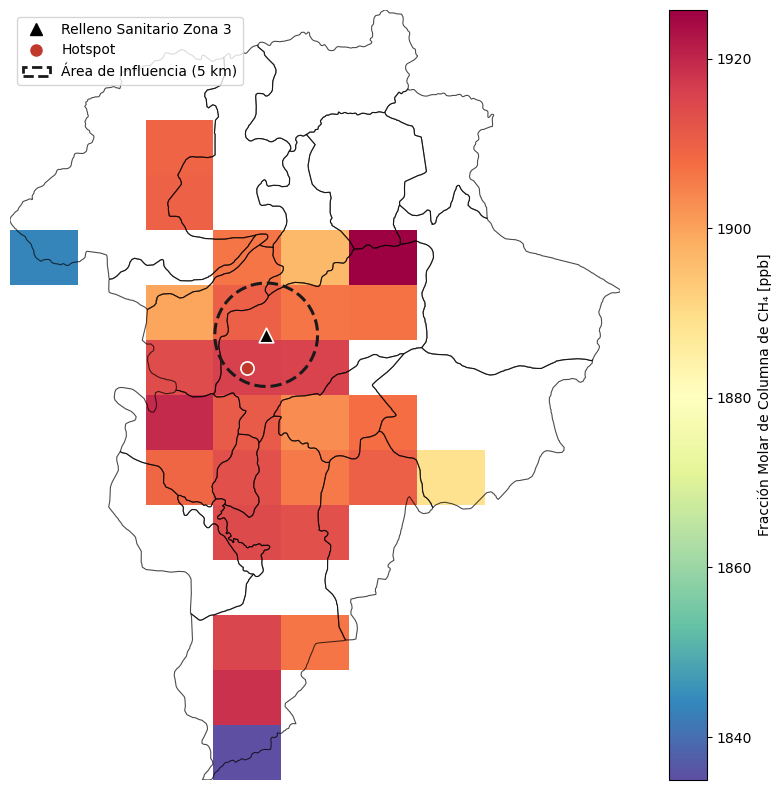

In [23]:
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from shapely.geometry import Point
poligono_amg = gpd.read_file("mystorage/amg_limites.geojson")
lon_z3, lat_z3 = -90.531387, 14.631103
punto_vertedero = gpd.GeoDataFrame(
    {"Nombre": ["Relleno Sanitario Zona 3"]},
    geometry=[Point(lon_z3, lat_z3)],
    crs="EPSG:4326",
)

radio_km = 5.0
gdf_buffer_z3 = punto_vertedero.to_crs("EPSG:32615").buffer(radio_km * 1000)
gdf_buffer_z3 = gpd.GeoDataFrame(
    geometry=gdf_buffer_z3, crs="EPSG:32615"
).to_crs("EPSG:4326")

matriz_ch4 = (
    linea_base_ch4 if "linea_base_ch4" in locals() else ch4_linea_base
).rio.write_crs("EPSG:4326")

recorte_buffer_ch4 = matriz_ch4.rio.clip(
    gdf_buffer_z3.geometry, gdf_buffer_z3.crs, drop=True, all_touched=True
)

recorte_exterior_ch4 = matriz_ch4.rio.clip(
    gdf_buffer_z3.geometry,
    gdf_buffer_z3.crs,
    drop=False,
    invert=True,
    all_touched=True,
)

media_buffer = float(recorte_buffer_ch4.mean(skipna=True).values)
max_buffer = float(recorte_buffer_ch4.max(skipna=True).values)
media_amg = float(matriz_ch4.mean(skipna=True).values)
media_exterior = float(recorte_exterior_ch4.mean(skipna=True).values)

diferencia_ppb = media_buffer - media_exterior
porcentaje_sobre_exterior = (diferencia_ppb / media_exterior) * 100

print(
    f"Análisis de próximidad Relleno Sanitario Zona 3 (Buffer {radio_km} km) ==="
)
print(
    f"Concentración media en Zona de Influencia ({radio_km} km) : {media_buffer:.2f} ppb"
)
print(
    f"Concentración máxima dentro del Buffer             : {max_buffer:.2f} ppb"
)
print(
    f"Concentración media global del AMG                 : {media_amg:.2f} ppb"
)
print(
    f"Concentración media fuera del Buffer (Periferia)   : {media_exterior:.2f} ppb"
)
print(
    f"Anomalía local respecto al exterior del Buffer     : +{diferencia_ppb:.2f} ppb (+{porcentaje_sobre_exterior:.2f}%)"
)

fig, ax = plt.subplots(figsize=(10, 8))

matriz_ch4.plot(
    ax=ax,
    cmap="Spectral_r",
    cbar_kwargs={"label": "Fracción Molar de Columna de CH₄ [ppb]"},
)

poligono_amg.plot(
    ax=ax, facecolor="none", edgecolor="black", linewidth=0.8, alpha=0.7
)

gdf_buffer_z3.plot(
    ax=ax,
    facecolor="none",
    edgecolor="#1A1A1A",
    linewidth=2.2,
    linestyle="--",
    zorder=6,
)

punto_vertedero.plot(
    ax=ax,
    color="black",
    marker="^",
    markersize=110,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)
ax.scatter(
    -90.548436,
    14.602509,
    color="#C0392B",
    marker="o",
    s=90,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)

pin_basurero = mlines.Line2D(
    [],
    [],
    color="black",
    marker="^",
    linestyle="None",
    markersize=9,
    label="Relleno Sanitario Zona 3",
)
pin_hotspot = mlines.Line2D(
    [],
    [],
    color="#C0392B",
    marker="o",
    linestyle="None",
    markersize=8,
    label="Hotspot",
)
aro_buffer = mpatches.Patch(
    edgecolor="#1A1A1A",
    facecolor="none",
    linestyle="--",
    linewidth=2,
    label=f"Área de Influencia ({radio_km:.0f} km)",
)

ax.legend(
    handles=[pin_basurero, pin_hotspot, aro_buffer],
    loc="upper left",
    frameon=True,
    fontsize=10,
)

ax.set_title("")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

Comparativa de vertederos. (Buffers 5.0 km) ===
1. Relleno Sanitario Zona 3 (14°37'52"N, 90°31'53"W) : 1910.92 ppb (+10.75 ppb vs exterior) (+0.57%)
2. Vertedero AMSA - Villa Nueva                        : 1912.06 ppb (+11.88 ppb vs exterior) (+0.63%)
3. Fondo Metropolitano (Fuera de ambos buffers)        : 1900.18 ppb


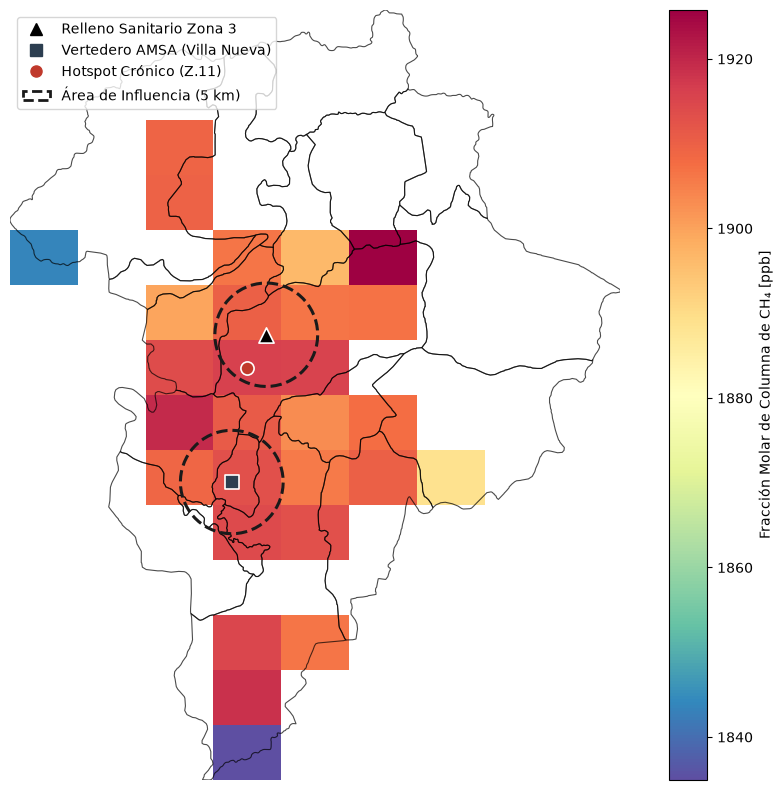

In [15]:
import geopandas as gpd
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import Point

lat_z3, lon_z3 = 14 + 37 / 60 + 52 / 3600, -(
    90 + 31 / 60 + 53 / 3600
)
lat_amsa, lon_amsa = 14.502500, -90.562500

gdf_vertederos = gpd.GeoDataFrame(
    {"Sitio": ["Relleno Sanitario Zona 3", "Vertedero AMSA (Villa Nueva)"]},
    geometry=[Point(lon_z3, lat_z3), Point(lon_amsa, lat_amsa)],
    crs="EPSG:4326",
)

radio_km = 5.0
buffers_utm = gdf_vertederos.to_crs("EPSG:32615").buffer(radio_km * 1000)
gdf_buffers = gpd.GeoDataFrame(
    {"Sitio": gdf_vertederos["Sitio"]}, geometry=buffers_utm, crs="EPSG:32615"
).to_crs("EPSG:4326")

matriz_ch4 = (
    linea_base_ch4 if "linea_base_ch4" in locals() else ch4_linea_base
).rio.write_crs("EPSG:4326")

recorte_z3 = matriz_ch4.rio.clip(
    [gdf_buffers.geometry.iloc[0]],
    gdf_buffers.crs,
    drop=True,
    all_touched=True,
)
recorte_amsa = matriz_ch4.rio.clip(
    [gdf_buffers.geometry.iloc[1]],
    gdf_buffers.crs,
    drop=True,
    all_touched=True,
)
recorte_exterior = matriz_ch4.rio.clip(
    gdf_buffers.geometry,
    gdf_buffers.crs,
    drop=False,
    invert=True,
    all_touched=True,
)

media_z3 = float(recorte_z3.mean(skipna=True).values)
media_amsa = float(recorte_amsa.mean(skipna=True).values)
media_ext = float(recorte_exterior.mean(skipna=True).values)
diferencia_ppb_z3 = media_z3 - media_ext
diferencia_ppb_amsa = media_amsa - media_ext
porcentaje_sobre_exterior_z3 = (
    diferencia_ppb_z3 / media_ext
) * 100

porcentaje_sobre_exterior_amsa = (
    diferencia_ppb_amsa / media_ext
) * 100
print(
    f"Comparativa de vertederos. (Buffers {radio_km} km) ==="
)
print(
    f"1. Relleno Sanitario Zona 3 (14°37'52\"N, 90°31'53\"W) : {media_z3:.2f} ppb (+{media_z3 - media_ext:.2f} ppb vs exterior) (+{porcentaje_sobre_exterior_z3:.2f}%)"
)
print(
    f"2. Vertedero AMSA - Villa Nueva                        : {media_amsa:.2f} ppb (+{media_amsa - media_ext:.2f} ppb vs exterior) (+{porcentaje_sobre_exterior_amsa:.2f}%)"
)
print(
    f"3. Fondo Metropolitano (Fuera de ambos buffers)        : {media_ext:.2f} ppb"
)

fig, ax = plt.subplots(figsize=(10, 8))

matriz_ch4.plot(
    ax=ax,
    cmap="Spectral_r",
    cbar_kwargs={"label": "Fracción Molar de Columna de CH₄ [ppb]"},
)
poligono_amg.plot(
    ax=ax, facecolor="none", edgecolor="black", linewidth=0.8, alpha=0.7
)

gdf_buffers.plot(
    ax=ax,
    facecolor="none",
    edgecolor="#1A1A1A",
    linewidth=2.2,
    linestyle="--",
    zorder=6,
)

ax.scatter(
    lon_z3,
    lat_z3,
    color="black",
    marker="^",
    s=120,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)
ax.scatter(
    lon_amsa,
    lat_amsa,
    color="#2C3E50",
    marker="s",
    s=100,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)
ax.scatter(
    -90.548436,
    14.602509,
    color="#C0392B",
    marker="o",
    s=90,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)

# Leyenda limpia
pin_z3 = mlines.Line2D(
    [],
    [],
    color="black",
    marker="^",
    linestyle="None",
    markersize=9,
    label="Relleno Sanitario Zona 3",
)
pin_amsa = mlines.Line2D(
    [],
    [],
    color="#2C3E50",
    marker="s",
    linestyle="None",
    markersize=8,
    label="Vertedero AMSA (Villa Nueva)",
)
pin_hot = mlines.Line2D(
    [],
    [],
    color="#C0392B",
    marker="o",
    linestyle="None",
    markersize=8,
    label="Hotspot Crónico (Z.11)",
)
aro_buf = mpatches.Patch(
    edgecolor="#1A1A1A",
    facecolor="none",
    linestyle="--",
    linewidth=2,
    label=f"Área de Influencia ({radio_km:.0f} km)",
)

ax.legend(
    handles=[pin_z3, pin_amsa, pin_hot, aro_buf],
    loc="upper left",
    frameon=True,
    fontsize=10,
)
ax.set_title("")
ax.axis("off")

plt.tight_layout()

plt.show()

Análisis de próximidad Relleno Sanitario Zona 3 (Buffer 5.0 km)
Concentración media en Zona de Influencia (5.0 km) : 1910.92 ppb
Concentración máxima dentro del Buffer             : 1916.01 ppb
Concentración media global del AMG                 : 1904.64 ppb
Concentración media en la periferia   : 1903.28 ppb
Anomalía local respecto al exterior del Buffer     : +7.65 ppb (+0.40%)


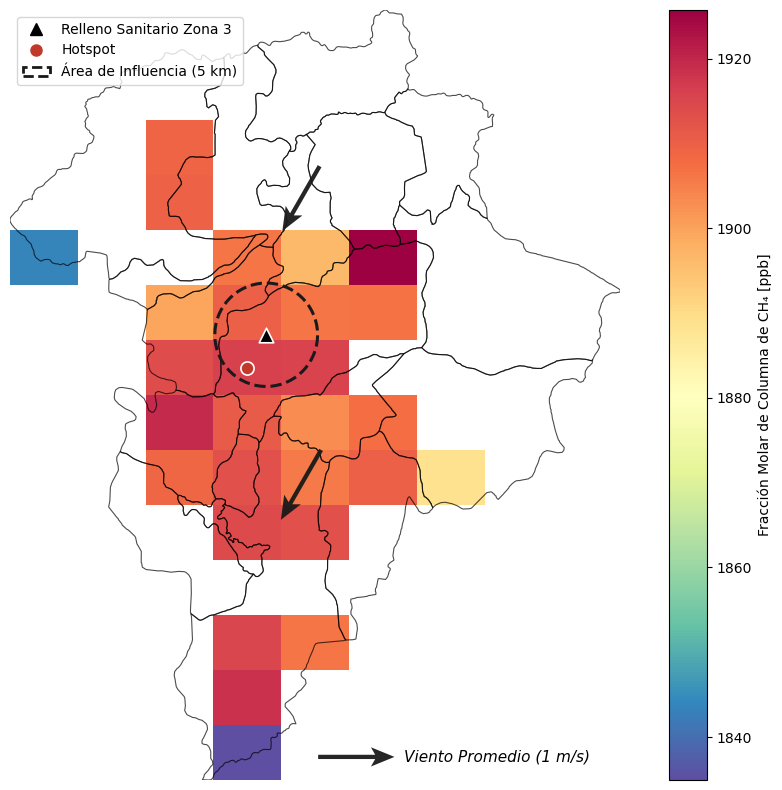

In [25]:
import geopandas as gpd
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import Point

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs("EPSG:4326")
lon_z3, lat_z3 = -90.531387, 14.631103

punto_vertedero = gpd.GeoDataFrame(
    {"Nombre": ["Relleno Sanitario Zona 3"]},
    geometry=[Point(lon_z3, lat_z3)],
    crs="EPSG:4326",
)

radio_km = 5.0
gdf_buffer_z3 = punto_vertedero.to_crs("EPSG:32615").buffer(radio_km * 1000)
gdf_buffer_z3 = gpd.GeoDataFrame(
    geometry=gdf_buffer_z3, crs="EPSG:32615"
).to_crs("EPSG:4326")

matriz_ch4 = (
    linea_base_ch4 if "linea_base_ch4" in locals() else ch4_linea_base
).rio.write_crs("EPSG:4326")

recorte_buffer_ch4 = matriz_ch4.rio.clip(
    gdf_buffer_z3.geometry, gdf_buffer_z3.crs, drop=True, all_touched=True
)
recorte_exterior_ch4 = matriz_ch4.rio.clip(
    gdf_buffer_z3.geometry,
    gdf_buffer_z3.crs,
    drop=False,
    invert=True,
    all_touched=True,
)

media_buffer = float(recorte_buffer_ch4.mean(skipna=True).values)
max_buffer = float(recorte_buffer_ch4.max(skipna=True).values)
media_amg = float(matriz_ch4.mean(skipna=True).values)
media_exterior = float(recorte_exterior_ch4.mean(skipna=True).values)

diferencia_ppb = media_buffer - media_exterior
porcentaje_sobre_exterior = (diferencia_ppb / media_exterior) * 100

print(f"Análisis de próximidad Relleno Sanitario Zona 3 (Buffer {radio_km} km)")
print(f"Concentración media en Zona de Influencia ({radio_km} km) : {media_buffer:.2f} ppb")
print(f"Concentración máxima dentro del Buffer             : {max_buffer:.2f} ppb")
print(f"Concentración media global del AMG                 : {media_amg:.2f} ppb")
print(f"Concentración media en la periferia   : {media_exterior:.2f} ppb")
print(f"Anomalía local respecto al exterior del Buffer     : +{diferencia_ppb:.2f} ppb (+{porcentaje_sobre_exterior:.2f}%)")

fig, ax = plt.subplots(figsize=(10, 8))

matriz_ch4.plot(
    ax=ax,
    cmap="Spectral_r",
    cbar_kwargs={"label": "Fracción Molar de Columna de CH₄ [ppb]"},
)

poligono_amg.plot(
    ax=ax, facecolor="none", edgecolor="black", linewidth=0.8, alpha=0.7
)

gdf_buffer_z3.plot(
    ax=ax,
    facecolor="none",
    edgecolor="#1A1A1A",
    linewidth=2.2,
    linestyle="--",
    zorder=6,
)

punto_vertedero.plot(
    ax=ax,
    color="black",
    marker="^",
    markersize=110,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)
ax.scatter(
    -90.548436,
    14.602509,
    color="#C0392B",
    marker="o",
    s=90,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)

viento_base = linea_base_viento if "linea_base_viento" in locals() else viento_linea_base
U = viento_base["u10"].values
V = viento_base["v10"].values
X = viento_base.longitude.values
Y = viento_base.latitude.values

q = ax.quiver(
    X, Y, U, V,
    color="#1A1A1A",
    pivot="middle",
    scale=8,
    width=0.0070,
    headwidth=4.5,
    headlength=5.5,
    alpha=0.95,
    zorder=8,
)

ax.quiverkey(
    q, X=0.63, Y=0.03, U=1,
    label="Viento Promedio (1 m/s)",
    labelpos="E",
    coordinates="axes",
    fontproperties={"size": 11, "style": "italic"},
)


pin_basurero = mlines.Line2D(
    [], [], color="black", marker="^", linestyle="None", markersize=9, label="Relleno Sanitario Zona 3"
)
pin_hotspot = mlines.Line2D(
    [], [], color="#C0392B", marker="o", linestyle="None", markersize=8, label="Hotspot"
)
aro_buffer = mpatches.Patch(
    edgecolor="#1A1A1A", facecolor="none", linestyle="--", linewidth=2, label=f"Área de Influencia ({radio_km:.0f} km)"
)

ax.legend(
    handles=[pin_basurero, pin_hotspot, aro_buffer],
    loc="upper left",
    frameon=True,
    fontsize=10,
)

ax.set_title("")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig(
    'Analisis_Proximidad_Z3_CH4_Viento.png', dpi=300, bbox_inches='tight'
)
plt.show()

Effecto de arrastre en buffer
Semicírculo Barlovento (Noreste / Entrada de aire) : 1910.92 ppb
Semicírculo Sotavento  (Suroeste / Zonas 8,11,12,13): 1913.89 ppb
Incremento a favor del viento (Efecto de Arrastre) : +2.97 ppb (+0.16%)


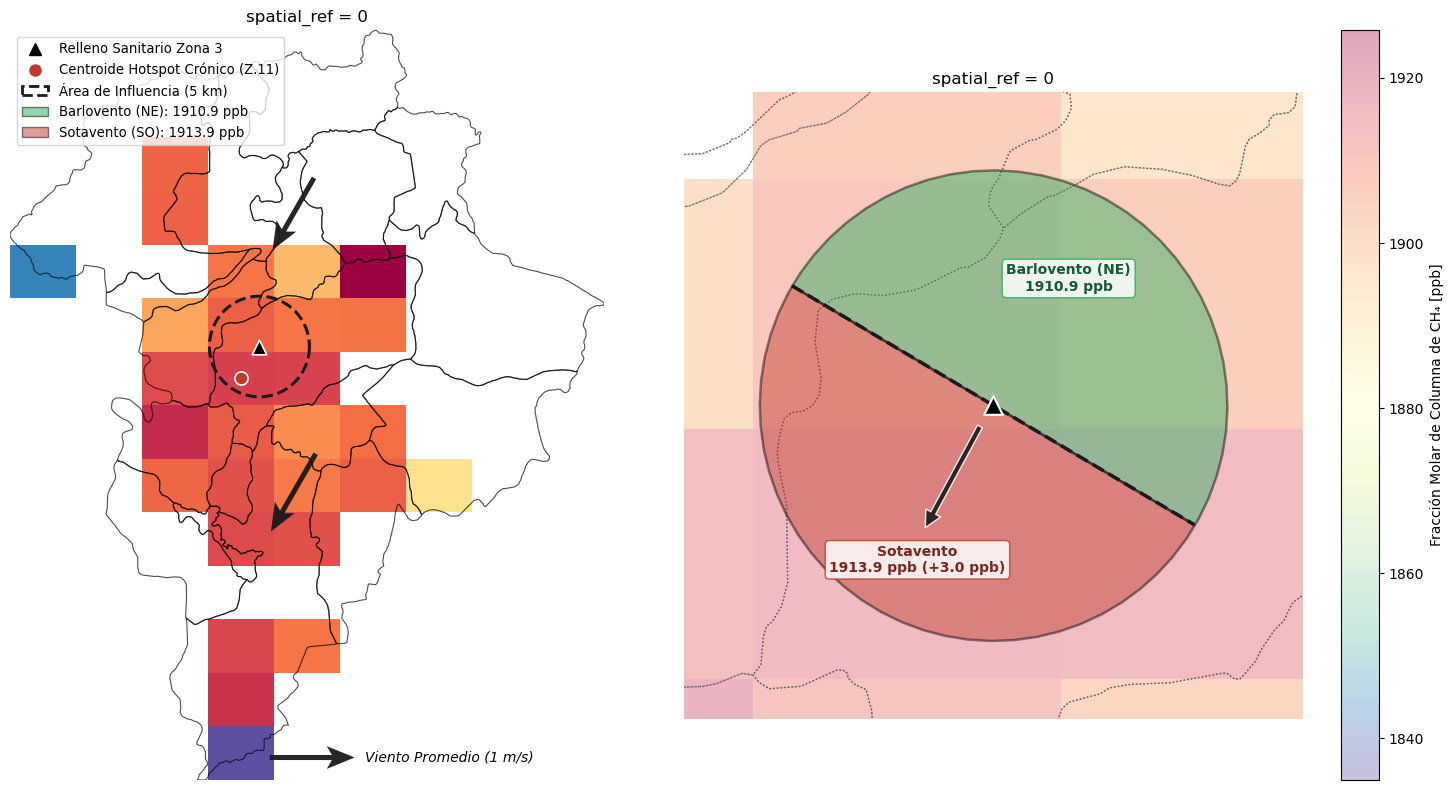

In [6]:
import geopandas as gpd
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import LineString, Point
from shapely.ops import split

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs(
    "EPSG:4326"
)
lon_z3, lat_z3 = -90.531387, 14.631103
lon_hot, lat_hot = -90.548436, 14.602509

punto_vertedero = gpd.GeoDataFrame(
    {"Nombre": ["Relleno Sanitario Zona 3"]},
    geometry=[Point(lon_z3, lat_z3)],
    crs="EPSG:4326",
)

radio_km = 5.0
gdf_buffer_z3 = gpd.GeoDataFrame(
    geometry=punto_vertedero.to_crs("EPSG:32615").buffer(radio_km * 1000),
    crs="EPSG:32615",
).to_crs("EPSG:4326")
poly_buffer = gdf_buffer_z3.geometry.iloc[0]

viento_base = (
    linea_base_viento
    if "linea_base_viento" in locals()
    else viento_linea_base
)
u_local = float(
    viento_base["u10"]
    .sel(longitude=lon_z3, latitude=lat_z3, method="nearest")
    .values
)
v_local = float(
    viento_base["v10"]
    .sel(longitude=lon_z3, latitude=lat_z3, method="nearest")
    .values
)

mag = np.hypot(u_local, v_local)
px, py = -v_local / mag, u_local / mag
d_deg = 0.08 

linea_corte = LineString(
    [
        (lon_z3 - px * d_deg, lat_z3 - py * d_deg),
        (lon_z3 + px * d_deg, lat_z3 + py * d_deg),
    ]
)

mitades = split(poly_buffer, linea_corte)
poly_barlovento, poly_sotavento = None, None

for geom in mitades.geoms:
    dx_c = geom.centroid.x - lon_z3
    dy_c = geom.centroid.y - lat_z3
    producto_punto = (dx_c * u_local) + (dy_c * v_local)
    if producto_punto > 0:
        poly_sotavento = geom 
    else:
        poly_barlovento = geom 

gdf_barlovento = gpd.GeoDataFrame(
    index=[0], geometry=[poly_barlovento], crs="EPSG:4326"
)
gdf_sotavento = gpd.GeoDataFrame(
    index=[0], geometry=[poly_sotavento], crs="EPSG:4326"
)

matriz_ch4 = (
    linea_base_ch4 if "linea_base_ch4" in locals() else ch4_linea_base
).rio.write_crs("EPSG:4326")

recorte_barlo = matriz_ch4.rio.clip(
    gdf_barlovento.geometry,
    gdf_barlovento.crs,
    drop=True,
    all_touched=True,
)
recorte_sota = matriz_ch4.rio.clip(
    gdf_sotavento.geometry, gdf_sotavento.crs, drop=True, all_touched=True
)

media_barlo = float(recorte_barlo.mean(skipna=True).values)
media_sota = float(recorte_sota.mean(skipna=True).values)
dif_arrastre_ppb = media_sota - media_barlo
dif_arrastre_pct = ((media_sota / media_barlo) - 1) * 100
----------

print(
    "Effecto de arrastre en buffer"
)
print(
    f"Semicírculo Barlovento (Noreste / Entrada de aire) : {media_barlo:.2f} ppb"
)
print(
    f"Semicírculo Sotavento  (Suroeste / Zonas 8,11,12,13): {media_sota:.2f} ppb"
)
print(
    f"Incremento a favor del viento (Efecto de Arrastre) : +{dif_arrastre_ppb:.2f} ppb (+{dif_arrastre_pct:.2f}%)"
)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1.05, 1]}
)

vmin_global = float(matriz_ch4.min(skipna=True).values)
vmax_global = float(matriz_ch4.max(skipna=True).values)

matriz_ch4.plot(
    ax=ax1,
    cmap="Spectral_r",
    vmin=vmin_global,
    vmax=vmax_global,
    add_colorbar=False,
)
poligono_amg.plot(
    ax=ax1, facecolor="none", edgecolor="black", linewidth=0.8, alpha=0.7
)
gdf_buffer_z3.plot(
    ax=ax1,
    facecolor="none",
    edgecolor="#1A1A1A",
    linewidth=2.2,
    linestyle="--",
    zorder=6,
)

ax1.scatter(
    lon_z3,
    lat_z3,
    color="black",
    marker="^",
    s=110,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)
ax1.scatter(
    lon_hot,
    lat_hot,
    color="#C0392B",
    marker="o",
    s=90,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)

U = viento_base["u10"].values
V = viento_base["v10"].values
X = viento_base.longitude.values
Y = viento_base.latitude.values

q1 = ax1.quiver(
    X,
    Y,
    U,
    V,
    color="#1A1A1A",
    pivot="middle",
    scale=7,
    width=0.0085,
    headwidth=4.5,
    headlength=5.5,
    alpha=0.95,
    zorder=8,
)
ax1.quiverkey(
    q1,
    X=0.58,
    Y=0.03,
    U=1,
    label="Viento Promedio (1 m/s)",
    labelpos="E",
    coordinates="axes",
    fontproperties={"size": 10, "style": "italic"},
)

ax1.axis("off")

matriz_ch4.plot(
    ax=ax2,
    cmap="Spectral_r",
    vmin=vmin_global,
    vmax=vmax_global,
    alpha=0.35,
    cbar_kwargs={"label": "Fracción Molar de Columna de CH₄ [ppb]"},
)
poligono_amg.plot(
    ax=ax2,
    facecolor="none",
    edgecolor="#555555",
    linewidth=1.0,
    linestyle=":",
    alpha=0.8,
)

gdf_barlovento.plot(
    ax=ax2,
    facecolor="#27AE60",
    edgecolor="black",
    linewidth=1.8,
    alpha=0.45,
    zorder=4,
)
gdf_sotavento.plot(
    ax=ax2,
    facecolor="#C0392B",
    edgecolor="black",
    linewidth=1.8,
    alpha=0.45,
    zorder=4,
)

gpd.GeoDataFrame(
    index=[0],
    geometry=[linea_corte.intersection(poly_buffer)],
    crs="EPSG:4326",
).plot(ax=ax2, color="#1A1A1A", linewidth=2.5, linestyle="--", zorder=5)

ax2.scatter(
    lon_z3,
    lat_z3,
    color="black",
    marker="^",
    s=180,
    edgecolor="white",
    linewidth=1.5,
    zorder=7,
)
ax2.scatter(
    lon_hot,
    lat_hot,
    color="#C0392B",
    marker="o",
    s=150,
    edgecolor="white",
    linewidth=1.5,
    zorder=7,
)

ax2.annotate(
    "",
    xy=(lon_hot + 0.003, lat_hot + 0.004),
    xytext=(lon_z3 - 0.002, lat_z3 - 0.003),
    arrowprops=dict(
        facecolor="#1A1A1A",
        edgecolor="white",
        shrink=0.05,
        width=4,
        headwidth=12,
        alpha=0.9,
    ),
    zorder=8,
)

ax2.text(
    lon_z3 + 0.015,
    lat_z3 + 0.022,
    f"Barlovento (NE)\n{media_barlo:.1f} ppb",
    fontsize=10,
    fontweight="bold",
    color="#145A32",
    ha="center",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="#27AE60",
        alpha=0.85,
    ),
    zorder=9,
)

ax2.text(
    lon_z3 - 0.015,
    lat_z3 - 0.032,
    f"Sotavento\n{media_sota:.1f} ppb (+{dif_arrastre_ppb:.1f} ppb)",
    fontsize=10,
    fontweight="bold",
    color="#78281F",
    ha="center",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="#C0392B",
        alpha=0.85,
    ),
    zorder=9,
)

minx, miny, maxx, maxy = gdf_buffer_z3.total_bounds
margen = 0.015
ax2.set_xlim(minx - margen, maxx + margen)
ax2.set_ylim(miny - margen, maxy + margen)

ax2.axis("off")

pin_basurero = mlines.Line2D(
    [],
    [],
    color="black",
    marker="^",
    linestyle="None",
    markersize=9,
    label="Relleno Sanitario Zona 3",
)
pin_hotspot = mlines.Line2D(
    [],
    [],
    color="#C0392B",
    marker="o",
    linestyle="None",
    markersize=8,
    label="Centroide Hotspot Crónico (Z.11)",
)
aro_buffer = mpatches.Patch(
    edgecolor="#1A1A1A",
    facecolor="none",
    linestyle="--",
    linewidth=2,
    label="Área de Influencia (5 km)",
)
parche_barlo = mpatches.Patch(
    facecolor="#27AE60",
    alpha=0.5,
    edgecolor="black",
    label=f"Barlovento (NE): {media_barlo:.1f} ppb",
)
parche_sota = mpatches.Patch(
    facecolor="#C0392B",
    alpha=0.5,
    edgecolor="black",
    label=f"Sotavento (SO): {media_sota:.1f} ppb",
)

ax1.legend(
    handles=[
        pin_basurero,
        pin_hotspot,
        aro_buffer,
        parche_barlo,
        parche_sota,
    ],
    loc="upper left",
    frameon=True,
    fontsize=9.5,
)

plt.tight_layout()
plt.show()import geopandas as gpd
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import LineString, Point
from shapely.ops import split

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs(
    "EPSG:4326"
)
lon_z3, lat_z3 = -90.531387, 14.631103
lon_hot, lat_hot = -90.548436, 14.602509

punto_vertedero = gpd.GeoDataFrame(
    {"Nombre": ["Relleno Sanitario Zona 3"]},
    geometry=[Point(lon_z3, lat_z3)],
    crs="EPSG:4326",
)

radio_km = 5.0
gdf_buffer_z3 = gpd.GeoDataFrame(
    geometry=punto_vertedero.to_crs("EPSG:32615").buffer(radio_km * 1000),
    crs="EPSG:32615",
).to_crs("EPSG:4326")
poly_buffer = gdf_buffer_z3.geometry.iloc[0]

viento_base = (
    linea_base_viento
    if "linea_base_viento" in locals()
    else viento_linea_base
)
u_local = float(
    viento_base["u10"]
    .sel(longitude=lon_z3, latitude=lat_z3, method="nearest")
    .values
)
v_local = float(
    viento_base["v10"]
    .sel(longitude=lon_z3, latitude=lat_z3, method="nearest")
    .values
)

mag = np.hypot(u_local, v_local)
px, py = -v_local / mag, u_local / mag
d_deg = 0.08 

linea_corte = LineString(
    [
        (lon_z3 - px * d_deg, lat_z3 - py * d_deg),
        (lon_z3 + px * d_deg, lat_z3 + py * d_deg),
    ]
)

mitades = split(poly_buffer, linea_corte)
poly_barlovento, poly_sotavento = None, None

for geom in mitades.geoms:
    dx_c = geom.centroid.x - lon_z3
    dy_c = geom.centroid.y - lat_z3
    producto_punto = (dx_c * u_local) + (dy_c * v_local)
    if producto_punto > 0:
        poly_sotavento = geom 
    else:
        poly_barlovento = geom 

gdf_barlovento = gpd.GeoDataFrame(
    index=[0], geometry=[poly_barlovento], crs="EPSG:4326"
)
gdf_sotavento = gpd.GeoDataFrame(
    index=[0], geometry=[poly_sotavento], crs="EPSG:4326"
)

matriz_ch4 = (
    linea_base_ch4 if "linea_base_ch4" in locals() else ch4_linea_base
).rio.write_crs("EPSG:4326")

recorte_barlo = matriz_ch4.rio.clip(
    gdf_barlovento.geometry,
    gdf_barlovento.crs,
    drop=True,
    all_touched=True,
)
recorte_sota = matriz_ch4.rio.clip(
    gdf_sotavento.geometry, gdf_sotavento.crs, drop=True, all_touched=True
)

media_barlo = float(recorte_barlo.mean(skipna=True).values)
media_sota = float(recorte_sota.mean(skipna=True).values)
dif_arrastre_ppb = media_sota - media_barlo
dif_arrastre_pct = ((media_sota / media_barlo) - 1) * 100
----------

print(
    "Effecto de arrastre en buffer"
)
print(
    f"Semicírculo Barlovento (Noreste / Entrada de aire) : {media_barlo:.2f} ppb"
)
print(
    f"Semicírculo Sotavento  (Suroeste / Zonas 8,11,12,13): {media_sota:.2f} ppb"
)
print(
    f"Incremento a favor del viento (Efecto de Arrastre) : +{dif_arrastre_ppb:.2f} ppb (+{dif_arrastre_pct:.2f}%)"
)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1.05, 1]}
)

vmin_global = float(matriz_ch4.min(skipna=True).values)
vmax_global = float(matriz_ch4.max(skipna=True).values)

matriz_ch4.plot(
    ax=ax1,
    cmap="Spectral_r",
    vmin=vmin_global,
    vmax=vmax_global,
    add_colorbar=False,
)
poligono_amg.plot(
    ax=ax1, facecolor="none", edgecolor="black", linewidth=0.8, alpha=0.7
)
gdf_buffer_z3.plot(
    ax=ax1,
    facecolor="none",
    edgecolor="#1A1A1A",
    linewidth=2.2,
    linestyle="--",
    zorder=6,
)

ax1.scatter(
    lon_z3,
    lat_z3,
    color="black",
    marker="^",
    s=110,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)
ax1.scatter(
    lon_hot,
    lat_hot,
    color="#C0392B",
    marker="o",
    s=90,
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)

U = viento_base["u10"].values
V = viento_base["v10"].values
X = viento_base.longitude.values
Y = viento_base.latitude.values

q1 = ax1.quiver(
    X,
    Y,
    U,
    V,
    color="#1A1A1A",
    pivot="middle",
    scale=7,
    width=0.0085,
    headwidth=4.5,
    headlength=5.5,
    alpha=0.95,
    zorder=8,
)
ax1.quiverkey(
    q1,
    X=0.58,
    Y=0.03,
    U=1,
    label="Viento Promedio (1 m/s)",
    labelpos="E",
    coordinates="axes",
    fontproperties={"size": 10, "style": "italic"},
)

ax1.axis("off")

matriz_ch4.plot(
    ax=ax2,
    cmap="Spectral_r",
    vmin=vmin_global,
    vmax=vmax_global,
    alpha=0.35,
    cbar_kwargs={"label": "Fracción Molar de Columna de CH₄ [ppb]"},
)
poligono_amg.plot(
    ax=ax2,
    facecolor="none",
    edgecolor="#555555",
    linewidth=1.0,
    linestyle=":",
    alpha=0.8,
)

gdf_barlovento.plot(
    ax=ax2,
    facecolor="#27AE60",
    edgecolor="black",
    linewidth=1.8,
    alpha=0.45,
    zorder=4,
)
gdf_sotavento.plot(
    ax=ax2,
    facecolor="#C0392B",
    edgecolor="black",
    linewidth=1.8,
    alpha=0.45,
    zorder=4,
)

gpd.GeoDataFrame(
    index=[0],
    geometry=[linea_corte.intersection(poly_buffer)],
    crs="EPSG:4326",
).plot(ax=ax2, color="#1A1A1A", linewidth=2.5, linestyle="--", zorder=5)

ax2.scatter(
    lon_z3,
    lat_z3,
    color="black",
    marker="^",
    s=180,
    edgecolor="white",
    linewidth=1.5,
    zorder=7,
)
ax2.scatter(
    lon_hot,
    lat_hot,
    color="#C0392B",
    marker="o",
    s=150,
    edgecolor="white",
    linewidth=1.5,
    zorder=7,
)

ax2.annotate(
    "",
    xy=(lon_hot + 0.003, lat_hot + 0.004),
    xytext=(lon_z3 - 0.002, lat_z3 - 0.003),
    arrowprops=dict(
        facecolor="#1A1A1A",
        edgecolor="white",
        shrink=0.05,
        width=4,
        headwidth=12,
        alpha=0.9,
    ),
    zorder=8,
)

ax2.text(
    lon_z3 + 0.015,
    lat_z3 + 0.022,
    f"Barlovento (NE)\n{media_barlo:.1f} ppb",
    fontsize=10,
    fontweight="bold",
    color="#145A32",
    ha="center",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="#27AE60",
        alpha=0.85,
    ),
    zorder=9,
)

ax2.text(
    lon_z3 - 0.015,
    lat_z3 - 0.032,
    f"Sotavento\n{media_sota:.1f} ppb (+{dif_arrastre_ppb:.1f} ppb)",
    fontsize=10,
    fontweight="bold",
    color="#78281F",
    ha="center",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="#C0392B",
        alpha=0.85,
    ),
    zorder=9,
)

minx, miny, maxx, maxy = gdf_buffer_z3.total_bounds
margen = 0.015
ax2.set_xlim(minx - margen, maxx + margen)
ax2.set_ylim(miny - margen, maxy + margen)

ax2.axis("off")

pin_basurero = mlines.Line2D(
    [],
    [],
    color="black",
    marker="^",
    linestyle="None",
    markersize=9,
    label="Relleno Sanitario Zona 3",
)
pin_hotspot = mlines.Line2D(
    [],
    [],
    color="#C0392B",
    marker="o",
    linestyle="None",
    markersize=8,
    label="Centroide Hotspot Crónico (Z.11)",
)
aro_buffer = mpatches.Patch(
    edgecolor="#1A1A1A",
    facecolor="none",
    linestyle="--",
    linewidth=2,
    label="Área de Influencia (5 km)",
)
parche_barlo = mpatches.Patch(
    facecolor="#27AE60",
    alpha=0.5,
    edgecolor="black",
    label=f"Barlovento (NE): {media_barlo:.1f} ppb",
)
parche_sota = mpatches.Patch(
    facecolor="#C0392B",
    alpha=0.5,
    edgecolor="black",
    label=f"Sotavento (SO): {media_sota:.1f} ppb",
)

ax1.legend(
    handles=[
        pin_basurero,
        pin_hotspot,
        aro_buffer,
        parche_barlo,
        parche_sota,
    ],
    loc="upper left",
    frameon=True,
    fontsize=9.5,
)

plt.tight_layout()
plt.show()

Resultados estancamiento viento CH4
Meses válidos emparejados (n)                  : 20 de 84
Correlación de Pearson (Serie completa)        : r = 0.1550 (p = 5.1417e-01)
Correlación de Pearson (Sin outlier Feb-2020)  : r = 0.3514 (p = 1.4019e-01)


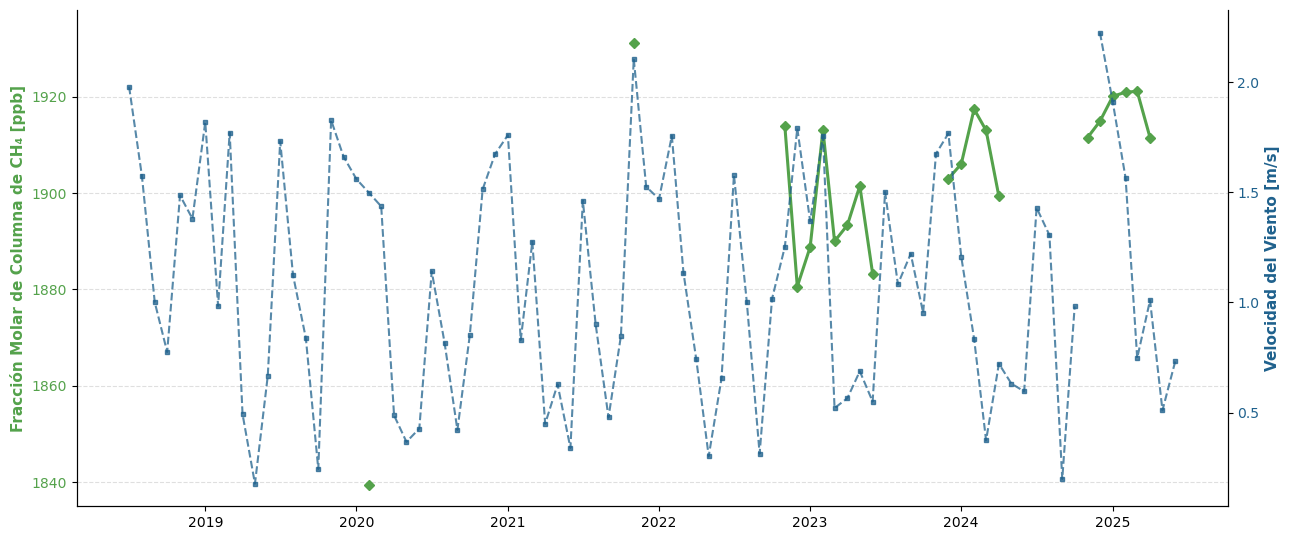

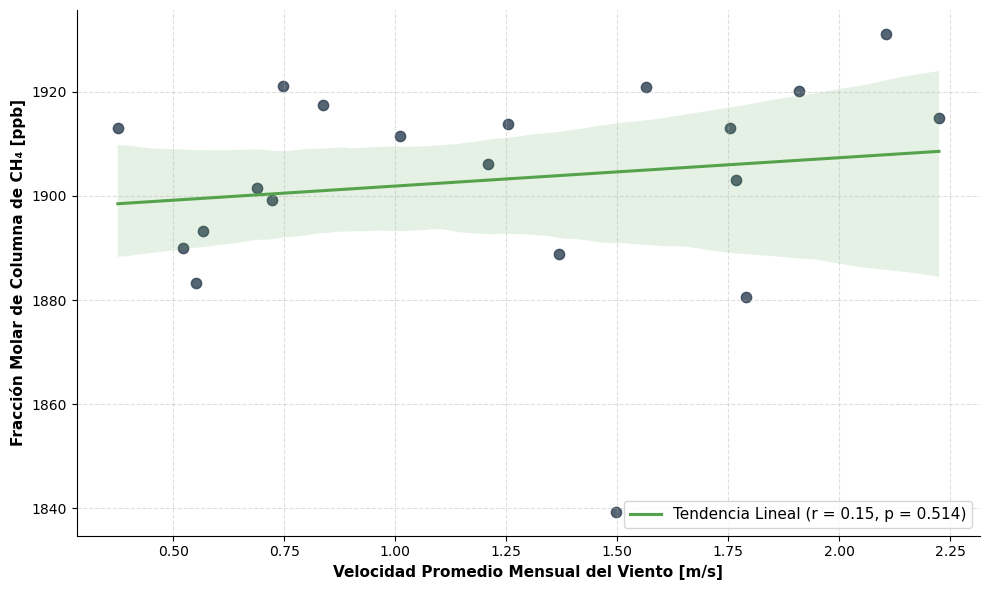

In [21]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns

if 'valid_time' in cubo_viento.dims or 'valid_time' in cubo_viento.coords:
  cubo_viento = cubo_viento.rename({'valid_time': 'time'})

velocidad_3d = np.sqrt(cubo_viento['u10'] ** 2 + cubo_viento['v10'] ** 2)

cubo_ch4_activo = (
    ch4_cube_masked if 'ch4_cube_masked' in locals() else cubo_ch4
)
ts_viento = velocidad_3d.mean(dim=['longitude', 'latitude'], skipna=True)
ts_ch4 = cubo_ch4_activo.mean(dim=['x', 'y'], skipna=True)

df_viento = ts_viento.to_dataframe(name='velocidad_viento').reset_index()
df_ch4 = ts_ch4.to_dataframe(name='ch4_ppb').reset_index()

df_viento['time'] = (
    pd.to_datetime(df_viento['time']).dt.to_period('M').dt.to_timestamp()
)
df_ch4['time'] = (
    pd.to_datetime(df_ch4['time']).dt.to_period('M').dt.to_timestamp()
)

df_temporal = pd.merge(
    df_viento[['time', 'velocidad_viento']],
    df_ch4[['time', 'ch4_ppb']],
    on='time',
    how='left',
)
df_estancamiento_ch4 = df_temporal.dropna(
    subset=['ch4_ppb', 'velocidad_viento']
).copy()

r_val, p_val = pearsonr(
    df_estancamiento_ch4['velocidad_viento'], df_estancamiento_ch4['ch4_ppb']
)

df_sin_outlier = df_estancamiento_ch4[df_estancamiento_ch4['ch4_ppb'] > 1860]
r_sin, p_sin = pearsonr(
    df_sin_outlier['velocidad_viento'], df_sin_outlier['ch4_ppb']
)

print('Resultados estancamiento viento CH4')
print(
    f'Meses válidos emparejados (n)                  : {len(df_estancamiento_ch4)} de 84'
)
print(
    f'Correlación de Pearson (Serie completa)        : r = {r_val:.4f} (p = {p_val:.4e})'
)
print(
    f'Correlación de Pearson (Sin outlier Feb-2020)  : r = {r_sin:.4f} (p = {p_sin:.4e})'
)

fig1, ax1 = plt.subplots(figsize=(13, 5.5))

color_ch4 = '#54A24B'
color_viento = '#1F618D'

ax1.plot(
    df_temporal['time'],
    df_temporal['ch4_ppb'],
    color=color_ch4,
    marker='D',
    markersize=5,
    linewidth=2.2,
    label='Concentración de CH₄',
)
ax1.set_ylabel(
    'Fracción Molar de Columna de CH₄ [ppb]',
    color=color_ch4,
    fontsize=11,
    fontweight='bold',
)
ax1.tick_params(axis='y', labelcolor=color_ch4)
ax1.set_ylim(1835, 1938)
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.grid(axis='y', linestyle='--', alpha=0.4)
ax1.spines['top'].set_visible(False)

ax2 = ax1.twinx()
ax2.plot(
    df_temporal['time'],
    df_temporal['velocidad_viento'],
    color=color_viento,
    linestyle='--',
    marker='s',
    markersize=3.5,
    linewidth=1.5,
    alpha=0.75,
    label='Velocidad del Viento (10m)',
)
ax2.set_ylabel(
    'Velocidad del Viento [m/s]',
    color=color_viento,
    fontsize=11,
    fontweight='bold',
)
ax2.tick_params(axis='y', labelcolor=color_viento)
ax2.spines['top'].set_visible(False)

ax1.set_title('')
plt.tight_layout()
plt.savefig('Dinamica_Temporal_CH4_Viento.png', dpi=300, bbox_inches='tight')
plt.show()

fig2, ax3 = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=df_estancamiento_ch4,
    x='velocidad_viento',
    y='ch4_ppb',
    ax=ax3,
    scatter_kws={'alpha': 0.8, 'color': '#2C3E50', 's': 55},
    line_kws={
        'color': '#54A24B',
        'linewidth': 2.2,
        'label': f'Tendencia Lineal (r = {r_val:.2f}, p = {p_val:.3f})',
    },
)

ax3.set_title('')
ax3.set_xlabel(
    'Velocidad Promedio Mensual del Viento [m/s]',
    fontsize=11,
    fontweight='bold',
)
ax3.set_ylabel(
    'Fracción Molar de Columna de CH₄ [ppb]',
    fontsize=11,
    fontweight='bold',
)
ax3.grid(True, linestyle='--', alpha=0.4)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.legend(loc='lower right', frameon=True, fontsize=11)

plt.tight_layout()
plt.savefig(
    'Regresion_Estancamiento_CH4_Viento.png', dpi=300, bbox_inches='tight'
)
plt.show()

/tmp/ipykernel_130/1443701216.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


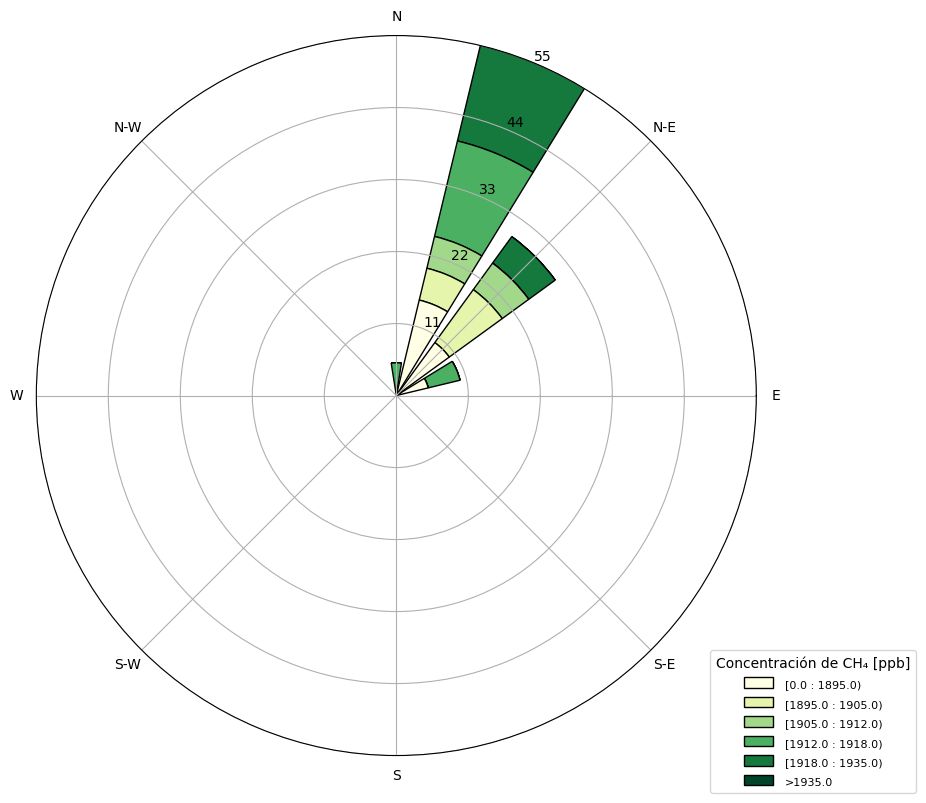

Rosa de Contaminación creada con 20 meses válidos.
Dirección media del viento en meses válidos: 33.8°


In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from windrose import WindroseAxes

ts_u = cubo_viento['u10'].mean(dim=['longitude', 'latitude'], skipna=True)
ts_v = cubo_viento['v10'].mean(dim=['longitude', 'latitude'], skipna=True)
cubo_ch4_activo = (
    ch4_cube_masked if 'ch4_cube_masked' in locals() else cubo_ch4
)
ts_ch4 = cubo_ch4_activo.mean(dim=['x', 'y'], skipna=True)

df_uv = pd.DataFrame({
    'time': (
        pd.to_datetime(ts_u.time.values).to_period('M').to_timestamp()
    ),
    'u_wind': ts_u.values,
    'v_wind': ts_v.values,
})

df_gas = pd.DataFrame({
    'time': (
        pd.to_datetime(ts_ch4.time.values).to_period('M').to_timestamp()
    ),
    'ch4_ppb': ts_ch4.values,
})

df_rosa_ch4 = pd.merge(df_gas, df_uv, on='time').dropna()

df_rosa_ch4['direccion_viento'] = (
    180 + np.degrees(np.arctan2(df_rosa_ch4['u_wind'], df_rosa_ch4['v_wind']))
) % 360

fig = plt.figure(figsize=(9, 9))
ax = WindroseAxes.from_ax(fig=fig)

ax.bar(
    direction=df_rosa_ch4['direccion_viento'],
    var=df_rosa_ch4['ch4_ppb'],
    normed=True,
    opening=0.8,
    edgecolor='black',
    cmap=plt.cm.YlGn,
    bins=[0, 1895, 1905, 1912, 1918, 1935],
)

ax.set_legend(
    title='Concentración de CH₄ [ppb]',
    loc='lower right',
    bbox_to_anchor=(1.22, -0.05),
    fontsize=10.5,
)

plt.title('')
plt.tight_layout()
plt.savefig('Pollution_Wind_Rose_CH4.png', dpi=300, bbox_inches='tight')
plt.show()

print(
    f'Rosa de Contaminación creada con {len(df_rosa_ch4)} meses válidos.'
)
print(
    'Dirección media del viento en meses válidos:'
    f" {df_rosa_ch4['direccion_viento'].mean():.1f}°"
)

In [7]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point

pd.options.future.infer_string = False

matriz_ch4 = (
    linea_base_ch4 if "linea_base_ch4" in locals() else ch4_linea_base
).astype("float32")
matriz_ch4 = matriz_ch4.rio.write_crs("EPSG:4326")
matriz_ch4.rio.to_raster("Linea_Base_CH4_QGIS.tif")

lon_z3, lat_z3 = -90.531387, 14.631103
gdf_vertedero = gpd.GeoDataFrame(
    {"id": [1]},
    geometry=[Point(lon_z3, lat_z3)],
    crs="EPSG:4326",
)
gdf_vertedero.to_file("Punto_Vertedero_Z3.geojson", driver="GeoJSON")

gdf_buffer_z3 = gpd.GeoDataFrame(
    {"id": [1]},
    geometry=gdf_vertedero.to_crs("EPSG:32615").buffer(5000),
    crs="EPSG:32615",
).to_crs("EPSG:4326")
gdf_buffer_z3.to_file("Buffer_5km_Z3.geojson", driver="GeoJSON")

gdf_hotspot_z11 = gpd.GeoDataFrame(
    {"id": [1]},
    geometry=[Point(-90.548436, 14.602509)],
    crs="EPSG:4326",
)
gdf_hotspot_z11.to_file("Punto_Hotspot_Z11.geojson", driver="GeoJSON")

if "gdf_barlovento" in locals() and "gdf_sotavento" in locals():
    gdf_barlovento[["geometry"]].to_file(
        "Barlovento_Z3.geojson", driver="GeoJSON"
    )
    gdf_sotavento[["geometry"]].to_file(
        "Sotavento_Z3.geojson", driver="GeoJSON"
    )

print("Archivos exportados")

Archivos exportados


In [17]:
import geopandas as gpd
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import rioxarray
import xarray as xr

from pyproj import Geod, Transformer
from shapely.geometry import LineString, Point
from shapely.ops import split

poligono_amg = gpd.read_file(
    "amg_limites.geojson"
).to_crs("EPSG:4326")

lon_z3, lat_z3 = -90.531387, 14.631103
lon_hot, lat_hot = -90.548436, 14.602509

radio_km = 5.0
radio_m = radio_km * 1000

matriz_ch4 = (
    linea_base_ch4
    .transpose("y", "x")
    .rio.write_crs("EPSG:4326")
)
matriz_ch4 = matriz_ch4.where(np.isfinite(matriz_ch4))

viento_base = linea_base_viento

u_local = float(
    viento_base["u10"].sel(
        longitude=lon_z3,
        latitude=lat_z3,
        method="nearest"
    ).item()
)

v_local = float(
    viento_base["v10"].sel(
        longitude=lon_z3,
        latitude=lat_z3,
        method="nearest"
    ).item()
)

mag = np.hypot(u_local, v_local)

if not np.isfinite(mag) or mag < 1e-8:
    raise ValueError(
        "El vector de viento no permite definir los sectores."
    )

azimut_destino = np.degrees(
    np.arctan2(u_local, v_local)
) % 360

direccion_procedencia = (azimut_destino + 180) % 360

transformador = Transformer.from_crs(
    "EPSG:4326", "EPSG:32615", always_xy=True
)
geod = Geod(ellps="WGS84")

x0, y0 = transformador.transform(lon_z3, lat_z3)

lon_destino, lat_destino, _ = geod.fwd(
    lon_z3, lat_z3, azimut_destino, 1000
)
x_destino, y_destino = transformador.transform(
    lon_destino, lat_destino
)

vector_utm = np.array([
    x_destino - x0,
    y_destino - y0
])
vector_utm = vector_utm / np.linalg.norm(vector_utm)

buffer_utm = Point(x0, y0).buffer(radio_m)
perpendicular = np.array([-vector_utm[1], vector_utm[0]])

extremo_1 = np.array([x0, y0]) - perpendicular * 2 * radio_m
extremo_2 = np.array([x0, y0]) + perpendicular * 2 * radio_m

corte_utm = LineString([extremo_1, extremo_2])
mitades = list(split(buffer_utm, corte_utm).geoms)

if len(mitades) != 2:
    raise ValueError("No se obtuvieron exactamente dos sectores.")

sectores_utm = {}

for geom in mitades:
    desplazamiento = np.array([
        geom.centroid.x - x0,
        geom.centroid.y - y0
    ])
    sector = (
        "sotavento"
        if desplazamiento @ vector_utm > 0
        else "barlovento"
    )
    sectores_utm[sector] = geom

def a_geografico(geometria):
    return gpd.GeoDataFrame(
        geometry=[geometria],
        crs="EPSG:32615"
    ).to_crs("EPSG:4326")

gdf_buffer_z3 = a_geografico(buffer_utm)
gdf_barlovento = a_geografico(sectores_utm["barlovento"])
gdf_sotavento = a_geografico(sectores_utm["sotavento"])

poly_buffer = gdf_buffer_z3.geometry.iloc[0]
linea_corte = a_geografico(corte_utm).geometry.iloc[0]

punto_vertedero = gpd.GeoDataFrame(
    {"Nombre": ["Relleno Sanitario Zona 3"]},
    geometry=[Point(lon_z3, lat_z3)],
    crs="EPSG:4326"
)

recorte_buffer_ch4 = matriz_ch4.rio.clip(
    gdf_buffer_z3.geometry,
    gdf_buffer_z3.crs,
    drop=False,
    all_touched=True
)

lon_grid, lat_grid = np.meshgrid(
    matriz_ch4.x.values,
    matriz_ch4.y.values
)
x_grid, y_grid = transformador.transform(lon_grid, lat_grid)

proyeccion = (
    (x_grid - x0) * vector_utm[0]
    + (y_grid - y0) * vector_utm[1]
)

proyeccion = xr.DataArray(
    proyeccion,
    coords={"y": matriz_ch4.y, "x": matriz_ch4.x},
    dims=("y", "x")
)

recorte_barlo = recorte_buffer_ch4.where(proyeccion <= 0)
recorte_sota = recorte_buffer_ch4.where(proyeccion > 0)

n_barlo = int(recorte_barlo.count().item())
n_sota = int(recorte_sota.count().item())
n_buffer = int(recorte_buffer_ch4.count().item())

n_compartidas = int(
    (recorte_barlo.notnull() & recorte_sota.notnull())
    .sum()
    .item()
)

if n_compartidas != 0 or n_barlo + n_sota != n_buffer:
    raise ValueError("La asignación de celdas no es consistente.")

if n_barlo == 0 or n_sota == 0:
    raise ValueError(
        "Uno de los sectores no tiene celdas válidas. "
        "No se puede calcular el contraste."
    )

media_barlo = float(recorte_barlo.mean(skipna=True).item())
media_sota = float(recorte_sota.mean(skipna=True).item())

dif_arrastre_ppb = media_sota - media_barlo
dif_arrastre_pct = (
    dif_arrastre_ppb / media_barlo
) * 100

print("Contraste espacial entre sectores")
print(
    f"Dirección de procedencia del viento: "
    f"{direccion_procedencia:.1f}°"
)
print(f"Celdas válidas en el buffer: {n_buffer}")
print(f"Celdas compartidas entre sectores: {n_compartidas}")
print(
    f"Barlovento: {media_barlo:.2f} ppb "
    f"({n_barlo} celdas)"
)
print(
    f"Sotavento: {media_sota:.2f} ppb "
    f"({n_sota} celdas)"
)
print(
    f"Diferencia sotavento − barlovento: "
    f"{dif_arrastre_ppb:+.2f} ppb "
    f"({dif_arrastre_pct:+.2f}%)"
)

Contraste espacial entre sectores
Dirección de procedencia del viento: 29.9°
Celdas válidas en el buffer: 5
Celdas compartidas entre sectores: 0
Barlovento: 1907.67 ppb (3 celdas)
Sotavento: 1915.80 ppb (2 celdas)
Diferencia sotavento − barlovento: +8.13 ppb (+0.43%)
